# 2. Combined posterior

This notebook builds the combined posterior of PSR J0030+0451 from the eight inputs of notebook 1, one ingredient at a time, and writes it to `results/`.

The method extends the good/bad mixture model of Press (1996):

1. each input is described by a **good** component (a kernel density estimate of its samples) and a **bad** component (a broad Gaussian that allows for unknown model systematics);
2. **correlation tempering** stops the shared photons of the eight analyses from being counted eight times;
3. a **common systematic displacement** allows for a bias shared by all of them.

The whole notebook takes 2–3 minutes. With `RECOMPUTE = False` it loads the saved `results/combined_MC.npz` instead of running the full combination.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from j0030 import method, plotting

RECOMPUTE = True

## Grid and good components

The combination is evaluated on a grid in mass and compactness: $M$ from 0.95 to 2.2 $M_\odot$ and $C$ over the pooled range of the input samples, 80 × 80 points.

The good component $g_i(M, C)$ of input $i$ is a two-dimensional Gaussian kernel density estimate of its samples, with Silverman's bandwidth, normalized on the grid. A KDE keeps the skewed and multimodal shapes of the published posteriors, which a Gaussian would not.

Building the setup evaluates all eight KDEs (some inputs have up to $10^6$ samples) and all bad components, and takes about a minute.

In [2]:
S = method.Setup()
print(f"M grid: {S.M_grid[0]:.2f}-{S.M_grid[-1]:.2f} Msun ({len(S.M_grid)} points)")
print(f"C grid: {S.C_grid[0]:.4f}-{S.C_grid[-1]:.4f} ({len(S.C_grid)} points)")

M grid: 0.95-2.20 Msun (80 points)
C grid: 0.1004-0.2122 (80 points)


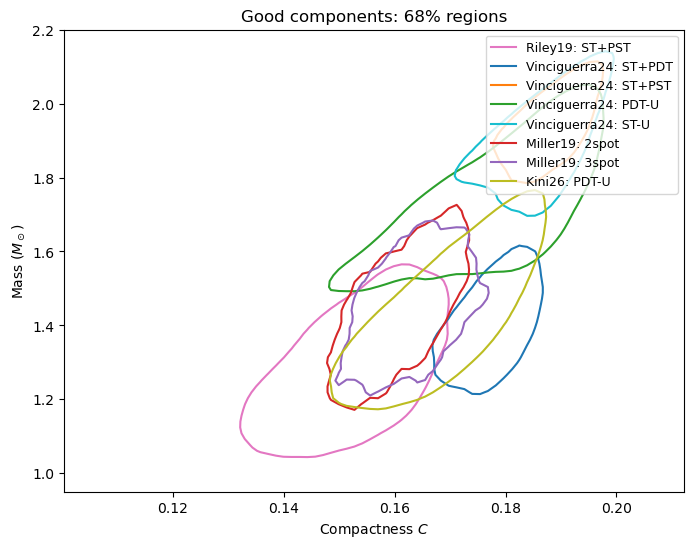

In [3]:
fig, ax = plt.subplots(figsize=(8, 6))
for i, key in enumerate(method.MODEL_KEYS):
    lvl95, lvl68 = method.hdr_levels(S.g_stack[i])
    ax.contour(S.C_grid, S.M_grid, S.g_stack[i], levels=[lvl68], colors=method.MODELS[key]["color"])
    ax.plot([], [], color=method.MODELS[key]["color"], label=method.label(key))
ax.set(xlabel="Compactness $C$", ylabel=r"Mass ($M_\odot$)", title="Good components: 68% regions")
ax.legend(fontsize=9);

## Bad components

The bad component of input $i$ is a Gaussian centred on the input's medians $(\bar M_i, \bar C_i)$:

$$
b_i(M, C \mid \alpha, \sigma) = \mathcal{N}\!\left(M;\ \bar M_i,\ \alpha^2 S_{M,i}^2 + \sigma_M^2\right)\,
\mathcal{N}\!\left(C;\ \bar C_i,\ \alpha^2 S_{C,i}^2 + \sigma_C^2\right).
$$

- **Baseline width.** $S_{a,i}$ is set so that the Gaussian's central 68% interval matches the input's central 99% interval: $S_{a,i} = \left[q_{99.5\%}(a) - q_{0.5\%}(a)\right] / \left[2\,\Phi^{-1}(0.84)\right]$.
- **Broadening.** $\alpha \geq 1$ has prior $\propto e^{-\alpha}$ on $[1, 10]$.
- **Shift.** A random displacement of the input enters as the extra variance $\sigma^2$, with prior $\propto 1/\sigma$ on a log grid.

Each input's likelihood is then the mixture

$$
\mathcal{L}_i(M, C \mid p, \sigma) = p\, g_i(M, C) + (1 - p)\, b_i(M, C \mid \sigma),
$$

with $\alpha$ marginalized and a mixing probability $p$ (flat prior on $[0, 1]$) shared by all inputs.

input                     median M     S_M  median C      S_C
Riley19: ST+PST              1.289   0.355    0.1533   0.0293
Vinciguerra24: ST+PDT        1.395   0.314    0.1773   0.0218
Vinciguerra24: ST+PST        1.927   0.376    0.1880   0.0164
Vinciguerra24: PDT-U         1.702   0.473    0.1791   0.0423
Vinciguerra24: ST-U          1.883   0.488    0.1861   0.0237
Miller19: 2spot              1.442   0.424    0.1603   0.0222
Miller19: 3spot              1.440   0.387    0.1631   0.0232
Kini26: PDT-U                1.435   0.487    0.1689   0.0363


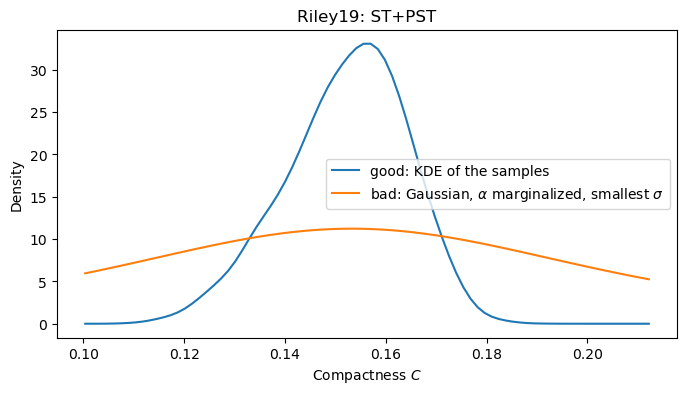

In [4]:
print(f"{'input':<24}{'median M':>10}{'S_M':>8}{'median C':>10}{'S_C':>9}")
for key in method.MODEL_KEYS:
    print(f"{method.label(key):<24}{S.M_med[key]:>10.3f}{S.S_M[key]:>8.3f}{S.C_med[key]:>10.4f}{S.S_C[key]:>9.4f}")

# Good vs bad component of one input, as compactness marginals.
i = method.MODEL_KEYS.index("ST_PST19")
g_C = method.trapz(S.g_stack[i], S.M_grid, axis=0)
b_C = method.trapz(S.b_all[i, 0, 0], S.M_grid, axis=0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(S.C_grid, g_C, label="good: KDE of the samples")
ax.plot(S.C_grid, b_C, label=r"bad: Gaussian, $\alpha$ marginalized, smallest $\sigma$")
ax.set(xlabel="Compactness $C$", ylabel="Density", title=method.label("ST_PST19"))
ax.legend();

## Correlation tempering

If the eight inputs were independent measurements, their likelihoods would simply be multiplied. They are not: most of them analyse the same NICER photons. Each mixture is therefore raised to a power before the product,

$$
\mathcal{L}(M, C \mid p, \sigma, \rho) = \prod_{i=1}^{N} \mathcal{L}_i(M, C \mid p, \sigma)^{\kappa(\rho)},
\qquad \kappa(\rho) = \frac{1}{1 + (N - 1)\rho},
$$

where $N = 8$ and $\rho$ is the effective correlation between inputs.

- $\rho = 0$ treats the inputs as independent ($\kappa = 1$).
- $\rho = 1$ counts them as a single measurement ($\kappa = 1/8$).

The correlation cannot be measured from the published posteriors, so $\rho$ is marginalized over a prior, $\mathrm{Uniform}(0, 1)$ for the adopted result.

Below, the combination at three fixed values of $\rho$, with $p$ and $\sigma$ marginalized:

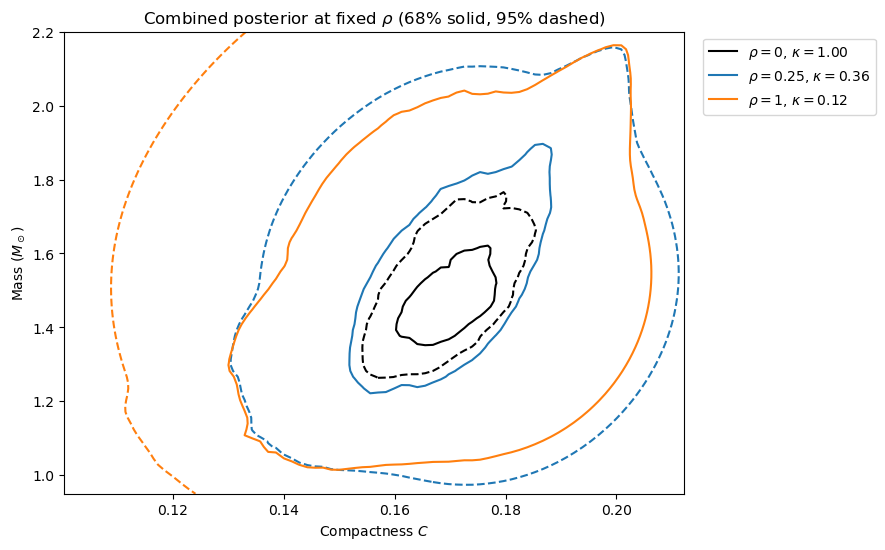

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
for rho, color in [(0.0, "black"), (0.25, "tab:blue"), (1.0, "tab:orange")]:
    kappa = method.design_effect_power(method.N_MODELS, rho)
    post = S.combine_given_kappa(kappa)[0]
    lvl95, lvl68 = method.hdr_levels(post)
    ax.contour(S.C_grid, S.M_grid, post, levels=[lvl95, lvl68], colors=color, linestyles=["--", "-"])
    ax.plot([], [], color=color, label=rf"$\rho = {rho:g}$, $\kappa = {kappa:.2f}$")
ax.set(xlabel="Compactness $C$", ylabel=r"Mass ($M_\odot$)",
       title="Combined posterior at fixed $\\rho$ (68% solid, 95% dashed)")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1));

## Common systematic displacement

The bad components allow each input to be offset on its own. A bias shared by all inputs (for example, from assumptions common to every analysis) would instead move the pooled posterior as a whole. It is modelled as a Gaussian convolution of the pooled posterior,

$$
p(M, C) \;\to\; p(M, C) * \mathcal{N}\!\left(0,\ \Sigma_{\rm sys}\right), \qquad
\Sigma_{\rm sys} = \mathrm{diag}\!\left(\sigma_{M,\rm sys}^2,\ \sigma_{C,\rm sys}^2\right),
$$

with half-normal priors on $\sigma_{M,\rm sys}$ and $\sigma_{C,\rm sys}$ whose scales are the spread (standard deviation) of the eight input medians:

In [6]:
print(f"scale of sigma_M,sys: {S.sys_scale_M:.4f} Msun")
print(f"scale of sigma_C,sys: {S.sys_scale_C:.5f}")

scale of sigma_M,sys: 0.2247 Msun
scale of sigma_C,sys: 0.01177


## Full combination

`method.run` sweeps $\rho$ over 21 values from 0 to 1, averages the posteriors over the $\rho$ prior, and applies the common systematic displacement. The result is mapped from $(M, C)$ to $(M, R)$ with the Jacobian $|\partial C / \partial R| = K M / R^2$.

It returns five scenarios:

| Scenario | $\rho$ | $\Sigma_{\rm sys}$ |
|---|---|---|
| `rho0` | 0 (independent) | none |
| `rho1` | 1 (fully dependent) | none |
| `beta41_nosys` | Beta(4, 1) prior | none |
| `uniform_nosys` | Uniform(0, 1) prior | none |
| `uniform_sys` (**adopted**) | Uniform(0, 1) prior | marginalized |

The results are saved to `results/combined_MC.npz`, together with 10,000 $(M, R)$ samples of the adopted posterior in `results/combined_posterior.txt`.

In [7]:
if RECOMPUTE:
    res = method.run(S)
    method.save_results(res)
else:
    res = method.load_results()

Sweeping rho over 21 points...


  done in 39 s
wrote results/combined_MC.npz
wrote results/combined_posterior.txt


## Adopted result

Medians and central 68% intervals of the adopted posterior:

In [8]:
d = method.summarize(res)
print(f"M = {method.fmt(d['M'], 2)} Msun")
print(f"R = {method.fmt(d['R'], 2)} km")
print(f"C = {method.fmt(d['C'], 3)}")

M = 1.53 +0.31/-0.27 Msun
R = 13.44 +2.95/-2.38 km
C = 0.169 +0.018/-0.021


## Effect of correlation tempering

The same summaries for every scenario. The last three columns give each 68% width relative to the independent ($\rho = 0$) result.

In [9]:
method.print_scenarios(res)

scenario                                                                 M (68%)                 R (68%)                 C (68%)  M/rho0  R/rho0  C/rho0
independent (rho = 0, no Sigma_sys)                          1.485 +0.097/-0.085       12.89 +0.70/-0.59  0.1704 +0.0053/-0.0065    1.00    1.00    1.00
fully dependent (rho = 1, no Sigma_sys)                      1.539 +0.364/-0.320       13.73 +3.76/-2.74  0.1674 +0.0231/-0.0302    3.76    5.02    4.53
rho ~ Beta(4, 1), no Sigma_sys                               1.533 +0.345/-0.294       13.59 +3.23/-2.44  0.1684 +0.0209/-0.0266    3.51    4.38    4.04
rho ~ Uniform(0, 1), no Sigma_sys                            1.514 +0.286/-0.216       13.27 +2.28/-1.63  0.1696 +0.0154/-0.0179    2.76    3.02    2.83
rho ~ Uniform(0, 1), Sigma_sys marginalized (adopted)        1.525 +0.314/-0.269       13.44 +2.95/-2.38  0.1691 +0.0180/-0.0211    3.20    4.11    3.32
(x/rho0 = 68% width relative to the rho = 0 result.)


## Density-agreement diagnostic on $\rho$

Renormalizing each tempered mixture and comparing the evidence across $\rho$ gives a distribution for $\rho$. It measures how much the eight densities **disagree**: broad, mutually inconsistent inputs favour a larger $\rho$. It does not measure their correlation, which posteriors alone cannot reveal. So it is reported only as a diagnostic, and the adopted result keeps the Uniform prior on $\rho$.

rho = 0.23 +0.38/-0.17


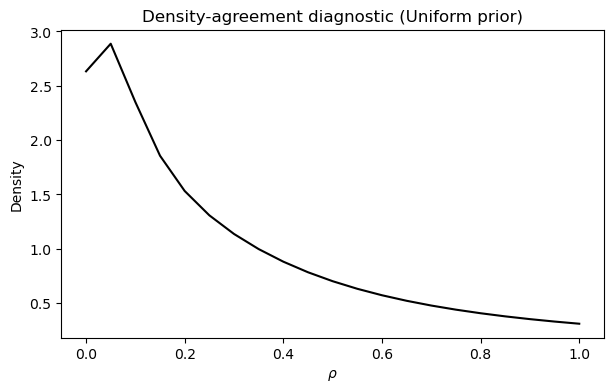

In [10]:
q = method.quantiles(res["RHO_GRID"], res["rho_posterior_uniform"])
print(f"rho = {method.fmt(q, 2)}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(res["RHO_GRID"], res["rho_posterior_uniform"], color="black")
ax.set(xlabel=r"$\rho$", ylabel="Density", title=r"Density-agreement diagnostic (Uniform prior)");

Next: **`3_Figures_and_Consistency.ipynb`** makes the paper's figures from `results/`.